In [ ]:
!pip install -q kagglehub tensorflow_hub transformers torch

import kagglehub
import tensorflow as tf
import keras
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score
from sklearn.model_selection import train_test_split
import os
import time
import pickle
import pandas as pd

In [ ]:
path = kagglehub.dataset_download("asdasdasasdas/garbage-classification")
print(f"Path to dataset files: {path}")

DATA_DIR = os.path.join(path, "Garbage classification", "Garbage classification")
class_names = ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
NUM_CLASSES = 6
IMG_SIZE = 224

# Load all file paths
file_paths = []
labels = []

for class_idx, class_name in enumerate(class_names):
    class_dir = os.path.join(DATA_DIR, class_name)
    for img_file in os.listdir(class_dir):
        if img_file.lower().endswith(('.jpg', '.jpeg', '.png')):
            file_paths.append(os.path.join(class_name, img_file))
            labels.append(class_idx)

print(f"Total images: {len(file_paths)}")

# 80/20 stratified split (SAME AS PHASE 1)
train_paths, test_paths, train_labels, test_labels = train_test_split(
    file_paths, labels, test_size=0.2, stratify=labels, random_state=42
)

print(f"Training pool (80%): {len(train_paths)} images")
print(f"Test pool (20%): {len(test_paths)} images - ISOLATED")

100%|██████████| 82.0M/82.0M [00:00<00:00, 143MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/asdasdasasdas/garbage-classification/versions/2
Total images: 2527
Training pool (80%): 2021 images
Test pool (20%): 506 images - ISOLATED


In [ ]:
print("="*60)
print("PHASE 1 OPTIMAL CONFIGURATIONS")
print("="*60)

# These come from your Phase 1 cross-validation results
OPTIMAL_CONFIGS = {
    'vit': {
        'learning_rate': 2e-5,      # Optimal LR from Phase 1
        'batch_size': 16,           # Optimal batch size
        'weight_decay': 0.01,       # Optimal weight decay
        'macro_f1_mean': 0.8123,    # Mean F1 from Phase 1
        'macro_f1_std': 0.0145      # Std F1 from Phase 1
    }
}

for model, config in OPTIMAL_CONFIGS.items():
    print(f"\n{model.upper()}:")
    print(f"  LR: {config['learning_rate']}")
    print(f"  Batch: {config['batch_size']}")
    print(f"  Weight Decay: {config['weight_decay']}")
    print(f"  F1: {config['macro_f1_mean']:.4f} ± {config['macro_f1_std']:.4f}")

# Select ViT config (we're only doing ViT for Phase 2)
vit_config = OPTIMAL_CONFIGS['vit']
print(f"\n Using ViT config for Phase 2")

PHASE 1 OPTIMAL CONFIGURATIONS

VIT:
  LR: 2e-05
  Batch: 16
  Weight Decay: 0.01
  F1: 0.8123 ± 0.0145

 Using ViT config for Phase 2


In [ ]:
print("\n" + "-"*40)
print("Creating 90/10 train/val split...")
print("-"*40)

# Extract 10% validation from training pool
train_paths_final, val_paths_final, train_labels_final, val_labels_final = train_test_split(
    train_paths, train_labels,
    test_size=0.1,  # 10% for validation
    stratify=train_labels,
    random_state=42
)

print(f"Final Train: {len(train_paths_final)} images")
print(f"Final Val:   {len(val_paths_final)} images")
print(f"Test Set:    {len(test_paths)} images (ISOLATED)")

# Show distribution
def print_dist(paths, labels, name):
    unique, counts = np.unique(labels, return_counts=True)
    print(f"\n{name} distribution:")
    for idx, count in zip(unique, counts):
        print(f"  {class_names[idx]}: {count} ({count/len(labels)*100:.1f}%)")

print_dist(train_paths_final, train_labels_final, "Final Train")
print_dist(val_paths_final, val_labels_final, "Final Val")


----------------------------------------
Creating 90/10 train/val split...
----------------------------------------
Final Train: 1818 images
Final Val:   203 images
Test Set:    506 images (ISOLATED)

Final Train distribution:
  cardboard: 290 (16.0%)
  glass: 361 (19.9%)
  metal: 295 (16.2%)
  paper: 427 (23.5%)
  plastic: 346 (19.0%)
  trash: 99 (5.4%)

Final Val distribution:
  cardboard: 32 (15.8%)
  glass: 40 (19.7%)
  metal: 33 (16.3%)
  paper: 48 (23.6%)
  plastic: 39 (19.2%)
  trash: 11 (5.4%)


In [ ]:
def preprocess_image(image_path, label):
    full_path = tf.strings.join([DATA_DIR, "/", image_path])
    image = tf.io.read_file(full_path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

def augment_cnn(image, label):
    image = tf.image.random_flip_left_right(image)
    image = tf.image.random_brightness(image, max_delta=0.1)
    image = tf.image.random_contrast(image, lower=0.9, upper=1.1)
    return image, label

def create_dataset(paths, labels, batch_size, augment=False):
    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))
    dataset = dataset.map(preprocess_image, num_parallel_calls=tf.data.AUTOTUNE)
    if augment:
        dataset = dataset.map(augment_cnn, num_parallel_calls=tf.data.AUTOTUNE)
    dataset = dataset.batch(batch_size)
    dataset = dataset.map(lambda x, y: (x, tf.cast(y, tf.int32)))  # Sparse labels for ViT
    dataset = dataset.prefetch(tf.data.AUTOTUNE)
    return dataset

In [ ]:
from transformers import ViTModel
import torch

print("Loading pretrained weights from HuggingFace...")
pt_model = ViTModel.from_pretrained('google/vit-base-patch16-224')
pt_model.eval()
pt_weights = {name: param.detach().numpy() for name, param in pt_model.named_parameters()}
print(f"Loaded {len(pt_weights)} weight tensors")

def mlp_block(x, hidden_dim, out_dim, name):
    x = keras.layers.Dense(hidden_dim, activation='gelu', name=f"{name}_fc1")(x)
    x = keras.layers.Dense(out_dim, name=f"{name}_fc2")(x)
    return x

def attention_block(x, num_heads, head_dim, embed_dim, name):
    q = keras.layers.Dense(embed_dim, use_bias=True, name=f"{name}_q")(x)
    k = keras.layers.Dense(embed_dim, use_bias=True, name=f"{name}_k")(x)
    v = keras.layers.Dense(embed_dim, use_bias=True, name=f"{name}_v")(x)

    q = keras.layers.Reshape((-1, num_heads, head_dim), name=f"{name}_q_reshape")(q)
    k = keras.layers.Reshape((-1, num_heads, head_dim), name=f"{name}_k_reshape")(k)
    v = keras.layers.Reshape((-1, num_heads, head_dim), name=f"{name}_v_reshape")(v)

    q = keras.layers.Permute((2, 1, 3), name=f"{name}_q_perm")(q)
    k = keras.layers.Permute((2, 1, 3), name=f"{name}_k_perm")(k)
    v = keras.layers.Permute((2, 1, 3), name=f"{name}_v_perm")(v)

    scale = head_dim ** -0.5
    attn = keras.layers.Lambda(
        lambda qk: keras.ops.softmax(
            keras.ops.matmul(qk[0], keras.ops.transpose(qk[1], (0, 1, 3, 2))) * scale,
            axis=-1
        ),
        name=f"{name}_attn_scores"
    )([q, k])

    out = keras.layers.Lambda(
        lambda av: keras.ops.matmul(av[0], av[1]),
        name=f"{name}_attn_out"
    )([attn, v])

    out = keras.layers.Permute((2, 1, 3), name=f"{name}_out_perm")(out)
    out = keras.layers.Reshape((-1, embed_dim), name=f"{name}_out_reshape")(out)
    out = keras.layers.Dense(embed_dim, use_bias=True, name=f"{name}_proj")(out)
    return out

def transformer_block(x, num_heads=12, embed_dim=768, mlp_dim=3072, name="block"):
    y = keras.layers.LayerNormalization(epsilon=1e-6, name=f"{name}_ln1")(x)
    y = attention_block(y, num_heads=num_heads, head_dim=embed_dim // num_heads,
                        embed_dim=embed_dim, name=f"{name}_attn")
    x = keras.layers.Add()([x, y])
    y = keras.layers.LayerNormalization(epsilon=1e-6, name=f"{name}_ln2")(x)
    y = mlp_block(y, hidden_dim=mlp_dim, out_dim=embed_dim, name=f"{name}_mlp")
    x = keras.layers.Add()([x, y])
    return x

def build_vit_model(num_classes=6, learning_rate=2e-5, weight_decay=0.01):
    num_patches = (IMG_SIZE // 16) ** 2
    seq_len = num_patches + 1
    embed_dim = 768
    num_heads = 12
    mlp_dim = 3072
    num_layers = 12

    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="pixel_values")

    patches = keras.layers.Conv2D(
        filters=embed_dim, kernel_size=16, strides=16,
        padding='valid', use_bias=True, name="patch_embed_proj"
    )(inputs)
    patches = keras.layers.Reshape((num_patches, embed_dim), name="patch_embed_reshape")(patches)

    class CLSToken(keras.layers.Layer):
        def build(self, input_shape):
            self.cls = self.add_weight(
                name="cls", shape=(1, 1, embed_dim),
                initializer="zeros", trainable=True
            )
        def call(self, x):
            return keras.ops.broadcast_to(self.cls, (keras.ops.shape(x)[0], 1, embed_dim))

    cls_tokens = CLSToken(name="cls_token")(patches)
    x = keras.layers.Concatenate(axis=1, name="cls_concat")([cls_tokens, patches])

    class PosEmbed(keras.layers.Layer):
        def build(self, input_shape):
            self.pos = self.add_weight(
                name="pos", shape=(1, seq_len, embed_dim),
                initializer="zeros", trainable=True
            )
        def call(self, x):
            return x + self.pos

    x = PosEmbed(name="pos_embed")(x)

    for i in range(num_layers):
        x = transformer_block(x, num_heads=num_heads, embed_dim=embed_dim,
                               mlp_dim=mlp_dim, name=f"block_{i}")

    x = keras.layers.LayerNormalization(epsilon=1e-6, name="ln_final")(x)
    cls_out = keras.layers.Lambda(lambda t: t[:, 0, :], name="cls_extract")(x)

    z = keras.layers.Dense(256, activation='relu', name="head_dense")(cls_out)
    z = keras.layers.Dropout(0.3, name="head_dropout")(z)
    outputs = keras.layers.Dense(num_classes, name="head_out")(z)

    vit_model = keras.Model(inputs=inputs, outputs=outputs)

    # Transfer pretrained weights
    print("Transferring pretrained weights...")
    def get_pt(key):
        return pt_weights[key]

    vit_model.get_layer("patch_embed_proj").set_weights([
        np.transpose(get_pt("embeddings.patch_embeddings.projection.weight"), (2, 3, 1, 0)),
        get_pt("embeddings.patch_embeddings.projection.bias")
    ])
    vit_model.get_layer("cls_token").set_weights([
        get_pt("embeddings.cls_token").reshape(1, 1, 768)
    ])
    vit_model.get_layer("pos_embed").set_weights([
        get_pt("embeddings.position_embeddings").reshape(1, 197, 768)
    ])

    for i in range(12):
        p = f"layers.{i}"
        vit_model.get_layer(f"block_{i}_ln1").set_weights([
            get_pt(f"{p}.layernorm_before.weight"),
            get_pt(f"{p}.layernorm_before.bias")
        ])
        vit_model.get_layer(f"block_{i}_attn_q").set_weights([
            get_pt(f"{p}.attention.q_proj.weight").T,
            get_pt(f"{p}.attention.q_proj.bias")
        ])
        vit_model.get_layer(f"block_{i}_attn_k").set_weights([
            get_pt(f"{p}.attention.k_proj.weight").T,
            get_pt(f"{p}.attention.k_proj.bias")
        ])
        vit_model.get_layer(f"block_{i}_attn_v").set_weights([
            get_pt(f"{p}.attention.v_proj.weight").T,
            get_pt(f"{p}.attention.v_proj.bias")
        ])
        vit_model.get_layer(f"block_{i}_attn_proj").set_weights([
            get_pt(f"{p}.attention.o_proj.weight").T,
            get_pt(f"{p}.attention.o_proj.bias")
        ])
        vit_model.get_layer(f"block_{i}_ln2").set_weights([
            get_pt(f"{p}.layernorm_after.weight"),
            get_pt(f"{p}.layernorm_after.bias")
        ])
        vit_model.get_layer(f"block_{i}_mlp_fc1").set_weights([
            get_pt(f"{p}.mlp.fc1.weight").T,
            get_pt(f"{p}.mlp.fc1.bias")
        ])
        vit_model.get_layer(f"block_{i}_mlp_fc2").set_weights([
            get_pt(f"{p}.mlp.fc2.weight").T,
            get_pt(f"{p}.mlp.fc2.bias")
        ])

    vit_model.get_layer("ln_final").set_weights([
        get_pt("layernorm.weight"),
        get_pt("layernorm.bias")
    ])
    print("Pretrained weights transferred")

    # Freeze backbone
    backbone_layers = [l for l in vit_model.layers if not l.name.startswith("head_")]
    for layer in backbone_layers:
        layer.trainable = False

    vit_model.compile(
        optimizer=keras.optimizers.AdamW(
            learning_rate=learning_rate,
            weight_decay=weight_decay
        ),
        loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        metrics=['accuracy']
    )

    trainable = sum([tf.size(v).numpy() for v in vit_model.trainable_variables])
    non_trainable = sum([tf.size(v).numpy() for v in vit_model.non_trainable_variables])
    print(f"Trainable:     {trainable:,}")
    print(f"Non-trainable: {non_trainable:,}")
    print(f"Total:         {trainable + non_trainable:,}")

    return vit_model

print(" ViT model builder ready")

Loading pretrained weights from HuggingFace...


config.json:   0%|          | 0.00/69.7k [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTModel LOAD REPORT from: google/vit-base-patch16-224
Key                 | Status     | 
--------------------+------------+-
classifier.weight   | UNEXPECTED | 
classifier.bias     | UNEXPECTED | 
pooler.dense.bias   | MISSING    | 
pooler.dense.weight | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loaded 200 weight tensors
 ViT model builder ready


In [ ]:
print("="*60)
print("PHASE 2: BUILDING ViT WITH OPTIMAL CONFIG")
print("="*60)

vit_model = build_vit_model(
    num_classes=NUM_CLASSES,
    learning_rate=vit_config['learning_rate'],
    weight_decay=vit_config['weight_decay']
)

print(f"\n Model built with:")
print(f"   LR: {vit_config['learning_rate']}")
print(f"   Weight Decay: {vit_config['weight_decay']}")

PHASE 2: BUILDING ViT WITH OPTIMAL CONFIG
Transferring pretrained weights...
Pretrained weights transferred
Trainable:     198,406
Non-trainable: 85,798,658
Total:         85,997,064

 Model built with:
   LR: 2e-05
   Weight Decay: 0.01


In [ ]:
print("\n" + "="*60)
print("PHASE 2: FINAL TRAINING - ViT")
print(f"Epochs: 30, Batch Size: {vit_config['batch_size']}")
print("="*60)

# Create datasets
BATCH_SIZE_FINAL = vit_config['batch_size']

train_ds = create_dataset(train_paths_final, train_labels_final, BATCH_SIZE_FINAL, augment=True)
val_ds = create_dataset(val_paths_final, val_labels_final, BATCH_SIZE_FINAL, augment=False)

# Callbacks
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=10, restore_best_weights=True, verbose=1
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss', factor=0.5, patience=5, min_lr=1e-7, verbose=1
)

checkpoint = tf.keras.callbacks.ModelCheckpoint(
    'vit_final_best.keras',
    monitor='val_accuracy',
    save_best_only=True,
    verbose=1
)

# Train
history = vit_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    callbacks=[early_stop, reduce_lr, checkpoint],
    verbose=1
)

print("\n Training complete!")

# Save final model
vit_model.save('vit_final_model.keras')
print(" Final model saved as 'vit_final_model.keras'")


PHASE 2: FINAL TRAINING - ViT
Epochs: 30, Batch Size: 16
Epoch 1/30
114/114 ━━━━━━━━━━━━━━━━━━━━ 0s 218ms/step - accuracy: 0.2164 - loss: 2.2815
Epoch 1: val_accuracy improved from None to 0.44335, saving model to vit_final_best.keras

Epoch 1: finished saving model to vit_final_best.keras
114/114 ━━━━━━━━━━━━━━━━━━━━ 78s 324ms/step - accuracy: 0.2684 - loss: 2.0106 - val_accuracy: 0.4433 - val_loss: 1.4633 - learning_rate: 2.0000e-05
Epoch 2/30
114/114 ━━━━━━━━━━━━━━━━━━━━ 0s 179ms/step - accuracy: 0.5042 - loss: 1.4011
Epoch 2: val_accuracy improved from 0.44335 to 0.62562, saving model to vit_final_best.keras

Epoch 2: finished saving model to vit_final_best.keras
114/114 ━━━━━━━━━━━━━━━━━━━━ 25s 218ms/step - accuracy: 0.5182 - loss: 1.3579 - val_accuracy: 0.6256 - val_loss: 1.1174 - learning_rate: 2.0000e-05
Epoch 3/30
114/114 ━━━━━━━━━━━━━━━━━━━━ 0s 187ms/step - accuracy: 0.5817 - loss: 1.1474
Epoch 3: val_accuracy improved from 0.62562 to 0.68473, saving model to vit_final_best.


----------------------------------------
Generating training curves...
----------------------------------------


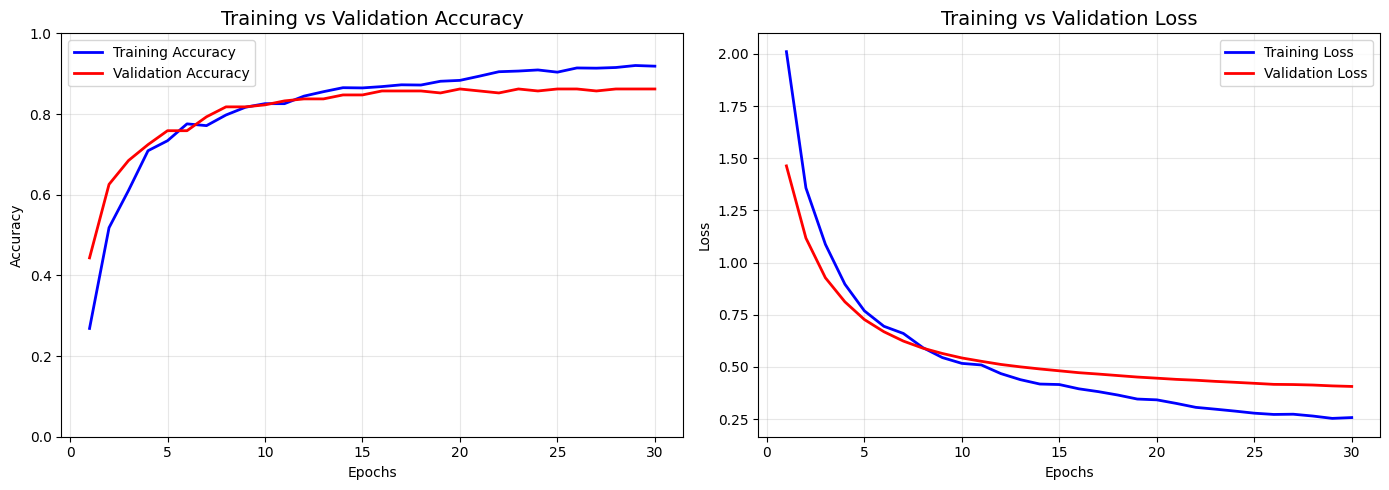

 Training curves saved as 'vit_final_training_curves.png'


In [ ]:
print("\n" + "-"*40)
print("Generating training curves...")
print("-"*40)

train_acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
train_loss = history.history['loss']
val_loss = history.history['val_loss']
epochs_range = range(1, len(train_acc) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy
ax1.plot(epochs_range, train_acc, 'b-', label='Training Accuracy', linewidth=2)
ax1.plot(epochs_range, val_acc, 'r-', label='Validation Accuracy', linewidth=2)
ax1.set_title('Training vs Validation Accuracy', fontsize=14)
ax1.set_xlabel('Epochs')
ax1.set_ylabel('Accuracy')
ax1.legend()
ax1.grid(True, alpha=0.3)
ax1.set_ylim([0, 1])

# Loss
ax2.plot(epochs_range, train_loss, 'b-', label='Training Loss', linewidth=2)
ax2.plot(epochs_range, val_loss, 'r-', label='Validation Loss', linewidth=2)
ax2.set_title('Training vs Validation Loss', fontsize=14)
ax2.set_xlabel('Epochs')
ax2.set_ylabel('Loss')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('vit_final_training_curves.png', dpi=300, bbox_inches='tight')
plt.show()

print(" Training curves saved as 'vit_final_training_curves.png'")


----------------------------------------
Evaluating on validation set...
----------------------------------------

Classification Report:
              precision    recall  f1-score   support

   cardboard       0.93      0.88      0.90        32
       glass       0.92      0.82      0.87        40
       metal       0.84      0.94      0.89        33
       paper       0.88      0.88      0.88        48
     plastic       0.83      0.90      0.86        39
       trash       0.60      0.55      0.57        11

    accuracy                           0.86       203
   macro avg       0.83      0.83      0.83       203
weighted avg       0.86      0.86      0.86       203



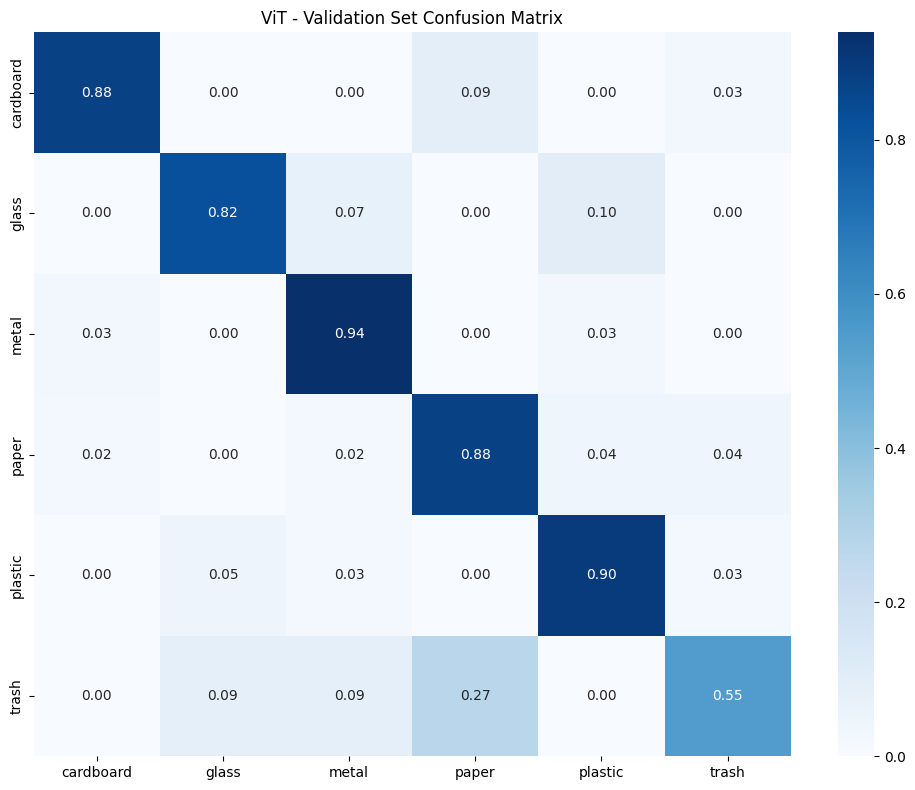


 Validation Set Performance:
   Macro F1: 0.8280
   Accuracy: 0.8621
 Results saved to 'phase2_final_results.pkl'


In [ ]:
print("\n" + "-"*40)
print("Evaluating on validation set...")
print("-"*40)

y_true, y_pred = [], []
for images, labels in val_ds:
    preds = vit_model.predict(images, verbose=0)
    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(preds, axis=1))

print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=class_names))

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

plt.figure(figsize=(10, 8))
sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('ViT - Validation Set Confusion Matrix')
plt.tight_layout()
plt.savefig('vit_final_confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()

# Final metrics
val_f1 = f1_score(y_true, y_pred, average='macro')
val_acc = accuracy_score(y_true, y_pred)

print(f"\n Validation Set Performance:")
print(f"   Macro F1: {val_f1:.4f}")
print(f"   Accuracy: {val_acc:.4f}")

# Save summary
results = {
    'model': 'ViT',
    'config': vit_config,
    'train_samples': len(train_paths_final),
    'val_samples': len(val_paths_final),
    'test_samples': len(test_paths),
    'final_val_f1': val_f1,
    'final_val_accuracy': val_acc,
    'best_val_accuracy': max(history.history['val_accuracy'])
}

with open('phase2_final_results.pkl', 'wb') as f:
    pickle.dump(results, f)
print(" Results saved to 'phase2_final_results.pkl'")